# 02 · SECOM exploratory analysis

**Goal:** understand 590 anonymised process measurements before predicting pass/fail.

**Questions**
1. How imbalanced is pass vs fail?
2. How much data is missing, and which features carry no information?
3. How redundant are the sensors?
4. Does the fail rate drift over time? (decides random vs time-based split)

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path

from wafer import eda
from wafer.data import load_secom, load_wm811k

FIG_DIR = Path("../reports/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.precision", 3)

In [2]:
X, meta = load_secom()
print(X.shape)
meta['fail'].value_counts()

(1567, 590)


fail
False    1463
True      104
Name: count, dtype: int64

## 1. Class balance

In [3]:
print(f"fail rate: {meta['fail'].mean():.1%}")

fail rate: 6.6%


## 2. Missing values and uninformative features

In [4]:
eda.missing_profile(X)

>0%     538
>5%      52
>20%     32
>50%     28
>80%      8
Name: n_features, dtype: int64

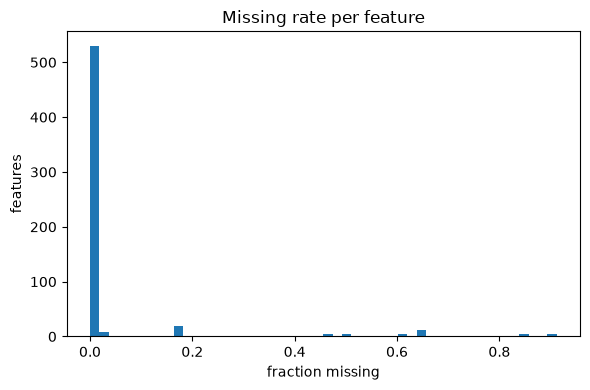

In [5]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(X.isna().mean(), bins=50)
ax.set_xlabel('fraction missing'); ax.set_ylabel('features')
ax.set_title('Missing rate per feature'); plt.tight_layout()
plt.savefig(FIG_DIR / 'secom_missing.png', dpi=150)

In [6]:
low = eda.low_information_features(X)
{k: len(v) for k, v in low.items()}

{'constant': 116, 'mostly_missing': 28}

## 3. Redundant sensors

In [7]:
pairs = eda.correlated_pairs(X.drop(columns=low['constant']), threshold=0.95)
print(f'{len(pairs)} feature pairs with |r| > 0.95')
pairs.head(10)

329 feature pairs with |r| > 0.95


,a,b,abs_r
0,f206,f209,1.0
1,f209,f478,1.0
2,f209,f347,1.0
3,f342,f347,1.0
4,f074,f209,1.0
5,f209,f342,1.0
6,f074,f478,1.0
7,f074,f347,1.0
8,f074,f342,1.0
9,f580,f588,1.0


## 4. Fail rate over time

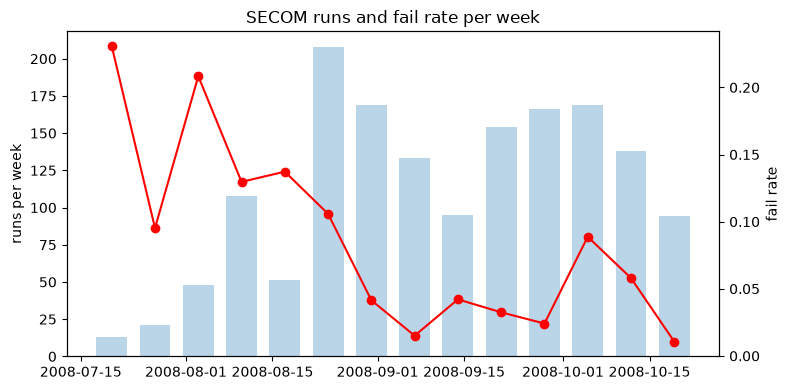

In [8]:
weekly = eda.fail_rate_over_time(meta)
fig, ax1 = plt.subplots(figsize=(8, 4))
ax1.bar(weekly.index, weekly['runs'], width=5, alpha=0.3, label='runs')
ax2 = ax1.twinx(); ax2.plot(weekly.index, weekly['fail_rate'], 'r-o', label='fail rate')
ax1.set_ylabel('runs per week'); ax2.set_ylabel('fail rate')
ax1.set_title('SECOM runs and fail rate per week'); plt.tight_layout()
plt.savefig(FIG_DIR / 'secom_fail_rate_time.png', dpi=150)

## Findings

**Data**
- **1,567 runs x 590 sensors, 104 fails (6.6%).** A model predicting "pass" every time is 93.4% accurate, so evaluation uses **PR-AUC and recall at a fixed false-alarm rate**, not accuracy.
- **Missing data is widespread but concentrated:** 538 of 590 features have some missing values, but only 52 are missing more than 5% of the time. 28 features are more than half empty and 8 are more than 80% empty.
- **116 features are constant** (one value or all missing) and carry no information.
- **Heavy redundancy:** 329 feature pairs have |r| > 0.95, with groups of sensors that are perfect copies of each other (e.g. f074, f206, f209, f342, f347, f478 all |r| = 1.0).
- After dropping constant and mostly-empty features, roughly **450 usable features** remain, and many of those are duplicates.

**Drift over time**
- The weekly fail rate falls from **~10–23% in July–August to mostly 1–6% from September (one 9% week in early October)**, while run volume rises. Early weeks have few runs, so part of this is noise, but the trend is clear.
- A random train/test split would mix early high-fail runs into both sets and **overstate model performance**. A time-ordered split is closer to how the model would be used in a fab.

**Decisions for step 3**
1. **Drop** the 116 constant and 28 mostly-empty features; impute the rest with the median fitted on training data only.
2. **Reduce redundancy** by keeping one feature from each highly correlated group, then compare against PCA.
3. **Split by time:** train on the earliest ~70% of runs and test on the latest ~30%. Also report stratified cross-validation for comparison.
4. **Models:** logistic regression baseline, then LightGBM/XGBoost with class weights; explain with SHAP.
